# Student Grade Prediction using C4.5 Decision Tree

This notebook uses **only a custom C4.5-style decision tree**. It does not use Random Forest or scikit-learn's Decision Tree as a prediction model.

Dataset: `Students Performance Dataset(2).csv` (5,000 rows, 23 columns)

**Target:** `Grade`

**Eight input features:**
- `Attendance (%)`
- `Midterm_Score`
- `Assignments_Avg`
- `Quizzes_Avg`
- `Participation_Score`
- `Projects_Score`
- `Study_Hours_per_Week`
- `Sleep_Hours_per_Night`

**Leakage prevention:** `Final_Score`, `Total_Score`, `Grade`, student IDs, names, and email addresses are not used as input features.

Keep the CSV in the same folder as this notebook.

## 1. Import libraries and load dataset

In [1]:


import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

DATA_PATH = "Students Performance Dataset.csv"
df_original = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_original.shape)
display(df_original.head())

Dataset shape: (5000, 23)


,Student_ID,First_Name,Last_Name,Email,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,...,Projects_Score,Total_Score,Grade,Study_Hours_per_Week,Extracurricular_Activities,Internet_Access_at_Home,Parent_Education_Level,Family_Income_Level,Stress_Level (1-10),Sleep_Hours_per_Night
0,S1000,Omar,Williams,student0@university.com,Female,22,Mathematics,97.36,40.61,59.61,...,62.84,59.8865,F,10.3,Yes,No,Master's,Medium,1,5.9
1,S1001,Maria,Brown,student1@university.com,Male,18,Business,97.71,57.27,74.00,...,98.23,81.9170,B,27.1,No,No,High School,Low,4,4.3
2,S1002,Ahmed,Jones,student2@university.com,Male,24,Engineering,99.52,41.84,63.85,...,91.22,67.7170,D,12.4,Yes,No,High School,Low,9,6.1
3,S1003,Omar,Williams,student3@university.com,Female,24,Engineering,90.38,45.65,44.44,...,55.48,51.6535,F,25.5,No,Yes,High School,Low,8,4.9
4,S1004,John,Smith,student4@university.com,Female,23,CS,59.41,53.13,61.77,...,87.43,71.4030,C,13.3,Yes,No,Master's,Medium,6,4.5


## 2. Inspect and clean data

In [2]:
print("Duplicate rows:", df_original.duplicated().sum())
print("Missing values by column:")
display(df_original.isna().sum().sort_values(ascending=False).to_frame("missing"))

df = df_original.drop_duplicates().copy()
df = df.dropna(subset=["Grade"]).reset_index(drop=True)
df["Grade"] = df["Grade"].astype(str).str.strip()

print("Cleaned dataset shape:", df.shape)
print("Grade classes:", sorted(df["Grade"].unique()))
display(df["Grade"].value_counts().to_frame("count"))

Duplicate rows: 0
Missing values by column:


,missing
Parent_Education_Level,1025
First_Name,0
Student_ID,0
Email,0
Gender,0
Age,0
Last_Name,0
Department,0
Attendance (%),0
Final_Score,0


Cleaned dataset shape: (5000, 23)
Grade classes: ['A', 'B', 'C', 'D', 'F']


,count
Grade,
C,2307
D,1760
B,638
F,279
A,16


## 3. Select the eight features

In [3]:
FEATURES = [
    "Attendance (%)",
    "Midterm_Score",
    "Assignments_Avg",
    "Quizzes_Avg",
    "Participation_Score",
    "Projects_Score",
    "Study_Hours_per_Week",
    "Sleep_Hours_per_Night",
]
TARGET = "Grade"

missing_cols = [col for col in FEATURES + [TARGET] if col not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# These selected features are numeric in this dataset.
X = df[FEATURES].copy()
for col in FEATURES:
    X[col] = pd.to_numeric(X[col], errors="coerce")
y = df[TARGET].to_numpy()

print("Feature count:", len(FEATURES))
print("Selected features:", FEATURES)
print("Target:", TARGET)
display(X.head())

Feature count: 8
Selected features: ['Attendance (%)', 'Midterm_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'Study_Hours_per_Week', 'Sleep_Hours_per_Night']
Target: Grade


,Attendance (%),Midterm_Score,Assignments_Avg,Quizzes_Avg,Participation_Score,Projects_Score,Study_Hours_per_Week,Sleep_Hours_per_Night
0,97.36,40.61,73.69,53.17,73.4,62.84,10.3,5.9
1,97.71,57.27,74.23,98.23,88.0,98.23,27.1,4.3
2,99.52,41.84,85.85,50.00,4.7,91.22,12.4,6.1
3,90.38,45.65,68.10,66.27,4.2,55.48,25.5,4.9
4,59.41,53.13,67.66,83.98,64.3,87.43,13.3,4.5


## 4. Explore grades and feature relationships

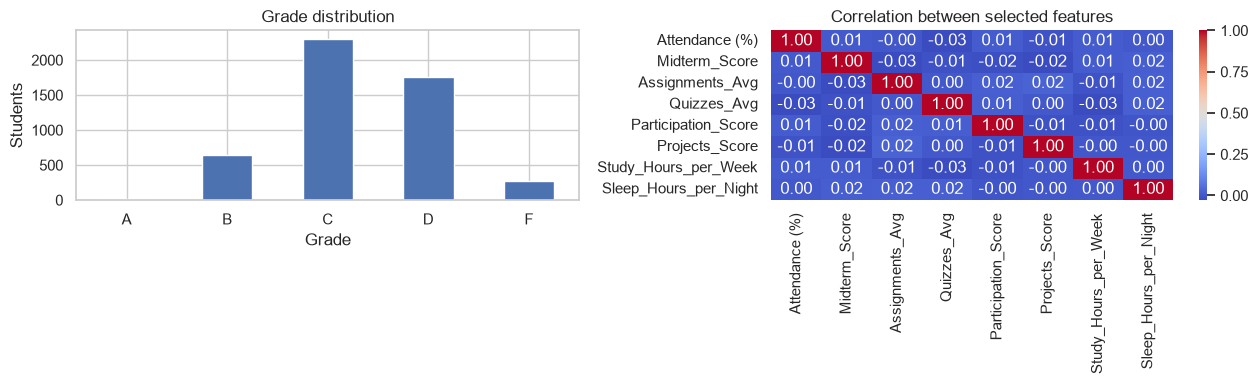

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df[TARGET].value_counts().sort_index().plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Grade distribution")
axes[0].set_xlabel("Grade")
axes[0].set_ylabel("Students")

sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Correlation between selected features")
plt.tight_layout()
plt.show()

## 5. Split the data

In [5]:

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

Training rows: 3000
Validation rows: 1000
Test rows: 1000


## 6. Implement C4.5-style algorithm

The implementation below uses:
- **Entropy** to measure class impurity.
- **Information Gain** to measure the improvement from a split.
- **Gain Ratio** to select split features while penalizing overly fragmented splits.
- **Threshold splits** for numeric features.
- **Pre-pruning** with maximum depth, minimum leaf size, and minimum gain.
- **Reduced-error post-pruning** using validation data.

This is a simplified educational C4.5-style implementation, not a claim of exact parity with every detail of the original C4.5 software.

In [6]:
def entropy(y):
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    p = counts / counts.sum()
    return float(-np.sum(p * np.log2(p + 1e-12)))


def majority_class(y):
    values, counts = np.unique(y, return_counts=True)
    return values[np.argmax(counts)]


class C45DecisionTree:
    def __init__(self, max_depth=6, min_samples_leaf=15, min_gain=1e-4):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_gain = min_gain
        self.tree_ = None
        self.feature_names_ = None

    def _candidate_thresholds(self, x, y):
        # Candidate thresholds only between adjacent distinct sorted values.
        order = np.argsort(x)
        xs = np.asarray(x, dtype=float)[order]
        ys = np.asarray(y)[order]
        candidates = []
        for i in range(1, len(xs)):
            if xs[i] == xs[i-1]:
                continue
            if ys[i] != ys[i-1]:
                candidates.append((xs[i] + xs[i-1]) / 2)
        return candidates

    def _split_score(self, y, left_mask):
        n = len(y)
        n_left = int(left_mask.sum())
        n_right = n - n_left
        if n_left < self.min_samples_leaf or n_right < self.min_samples_leaf:
            return None
        parent_entropy = entropy(y)
        left_y, right_y = y[left_mask], y[~left_mask]
        gain = parent_entropy - (
            len(left_y) / n * entropy(left_y) +
            len(right_y) / n * entropy(right_y)
        )
        p_left, p_right = n_left / n, n_right / n
        split_info = -(p_left * np.log2(p_left) + p_right * np.log2(p_right))
        gain_ratio = gain / split_info if split_info > 0 else 0.0
        return gain, gain_ratio

    def _best_split(self, X, y):
        candidates = []
        for feature in X.columns:
            values = X[feature].to_numpy(dtype=float)
            for threshold in self._candidate_thresholds(values, y):
                mask = values <= threshold
                score = self._split_score(y, mask)
                if score is not None:
                    gain, ratio = score
                    if gain > 0:
                        candidates.append({
                            "feature": feature,
                            "threshold": float(threshold),
                            "gain": float(gain),
                            "gain_ratio": float(ratio),
                        })

        if not candidates:
            return None

        # C4.5-style safeguard: first filter by average information gain,
        # then choose the candidate with the highest gain ratio.
        avg_gain = np.mean([c["gain"] for c in candidates])
        eligible = [c for c in candidates if c["gain"] >= avg_gain]
        return max(eligible or candidates, key=lambda c: c["gain_ratio"])

    def _build(self, X, y, depth):
        leaf = {"type": "leaf", "prediction": majority_class(y), "samples": len(y)}
        if (
            len(np.unique(y)) == 1
            or depth >= self.max_depth
            or len(y) < 2 * self.min_samples_leaf
        ):
            return leaf

        split = self._best_split(X, y)
        if split is None or split["gain"] < self.min_gain:
            return leaf

        feature, threshold = split["feature"], split["threshold"]
        mask = X[feature].to_numpy(dtype=float) <= threshold
        if mask.sum() == 0 or (~mask).sum() == 0:
            return leaf

        return {
            "type": "split",
            "feature": feature,
            "threshold": threshold,
            "prediction": leaf["prediction"],
            "samples": len(y),
            "gain": split["gain"],
            "gain_ratio": split["gain_ratio"],
            "left": self._build(X.loc[mask].reset_index(drop=True), y[mask], depth + 1),
            "right": self._build(X.loc[~mask].reset_index(drop=True), y[~mask], depth + 1),
        }

    def fit(self, X, y):
        X = X.reset_index(drop=True).copy()
        # Median-impute missing numeric feature values based on training data only.
        self.medians_ = X.median(numeric_only=True)
        X = X.fillna(self.medians_)
        self.feature_names_ = list(X.columns)
        self.tree_ = self._build(X, np.asarray(y), 0)
        return self

    def _predict_one(self, node, row):
        while node["type"] == "split":
            if row[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]
        return node["prediction"]

    def predict(self, X):
        X = X[self.feature_names_].copy().fillna(self.medians_)
        return np.array([
            self._predict_one(self.tree_, row)
            for row in X.to_dict(orient="records")
        ])

    def prune(self, X_val, y_val):
        X_val = X_val[self.feature_names_].copy().fillna(self.medians_).reset_index(drop=True)
        y_val = np.asarray(y_val)
        self.tree_ = self._prune_node(self.tree_, X_val, y_val)
        return self

    def _prune_node(self, node, Xv, yv):
        if node["type"] == "leaf":
            return node

        feature, threshold = node["feature"], node["threshold"]
        mask = Xv[feature].to_numpy(dtype=float) <= threshold

        node["left"] = self._prune_node(
            node["left"], Xv.loc[mask].reset_index(drop=True), yv[mask]
        )
        node["right"] = self._prune_node(
            node["right"], Xv.loc[~mask].reset_index(drop=True), yv[~mask]
        )

        if len(yv) == 0:
            return {"type": "leaf", "prediction": node["prediction"], "samples": node["samples"]}

        subtree_pred = np.array([self._predict_one(node, row)
                                 for row in Xv.to_dict(orient="records")])
        leaf_pred = np.repeat(node["prediction"], len(yv))
        # Replace subtree with majority-class leaf if validation accuracy does not decrease.
        if np.sum(leaf_pred != yv) <= np.sum(subtree_pred != yv):
            return {"type": "leaf", "prediction": node["prediction"], "samples": node["samples"]}
        return node


def print_tree(node, indent=""):
    if node["type"] == "leaf":
        print(indent + "Predict " + str(node["prediction"]) + f" (samples={node['samples']})")
        return
    print(indent + f"If {node['feature']} <= {node['threshold']:.3f}:")
    print_tree(node["left"], indent + "  ")
    print(indent + "Else:")
    print_tree(node["right"], indent + "  ")


def count_nodes(node):
    if node["type"] == "leaf":
        return 1
    return 1 + count_nodes(node["left"]) + count_nodes(node["right"])


def depth_of(node):
    if node["type"] == "leaf":
        return 0
    return 1 + max(depth_of(node["left"]), depth_of(node["right"]))


def collect_importance(node, result=None):
    if result is None:
        result = {}
    if node["type"] == "split":
        result[node["feature"]] = result.get(node["feature"], 0.0) + node["samples"] * node["gain"]
        collect_importance(node["left"], result)
        collect_importance(node["right"], result)
    return result

## 7. Tune the C4.5 tree using validation data only

In [7]:

tuning_rows = []

# Test only 6 combinations instead of 20
param_combinations = [
    (3, 15),
    (4, 15),
    (5, 15),
    (4, 25),
    (5, 25),
    (6, 25)
]

for depth, leaf_size in param_combinations:
    candidate = C45DecisionTree(
        max_depth=depth,
        min_samples_leaf=leaf_size
    )

    candidate.fit(X_train, y_train)
    candidate.prune(X_val, y_val)

    val_pred = candidate.predict(X_val)

    tuning_rows.append({
        "max_depth": depth,
        "min_samples_leaf": leaf_size,
        "validation_accuracy": accuracy_score(y_val, val_pred),
        "validation_macro_f1": f1_score(
            y_val, val_pred,
            average="macro",
            zero_division=0
        ),
        "nodes": count_nodes(candidate.tree_),
        "depth_after_pruning": depth_of(candidate.tree_)
    })

tuning = pd.DataFrame(tuning_rows).sort_values(
    ["validation_macro_f1", "validation_accuracy", "nodes"],
    ascending=[False, False, True]
).reset_index(drop=True)

display(tuning)

best_params = tuning.iloc[0]
BEST_DEPTH = int(best_params["max_depth"])
BEST_LEAF = int(best_params["min_samples_leaf"])

print("Chosen parameters:", {
    "max_depth": BEST_DEPTH,
    "min_samples_leaf": BEST_LEAF
})

,max_depth,min_samples_leaf,validation_accuracy,validation_macro_f1,nodes,depth_after_pruning
0,4,25,0.577,0.323147,19,4
1,5,25,0.577,0.323147,19,4
2,6,25,0.577,0.323147,19,4
3,5,15,0.573,0.308219,25,5
4,4,15,0.556,0.233612,11,4
5,3,15,0.551,0.231903,7,3


Chosen parameters: {'max_depth': 4, 'min_samples_leaf': 25}


## 8. Train, prune, and inspect the final C4.5 tree

In [8]:
c45_model = C45DecisionTree(max_depth=BEST_DEPTH, min_samples_leaf=BEST_LEAF)
c45_model.fit(X_train, y_train)

print("Before pruning — nodes:", count_nodes(c45_model.tree_), "| depth:", depth_of(c45_model.tree_))
c45_model.prune(X_val, y_val)
print("After pruning — nodes:", count_nodes(c45_model.tree_), "| depth:", depth_of(c45_model.tree_))
print("\nDecision rules:")
print_tree(c45_model.tree_)

Before pruning — nodes: 27 | depth: 4
After pruning — nodes: 19 | depth: 4

Decision rules:
If Projects_Score <= 74.955:
  If Midterm_Score <= 46.210:
    Predict D (samples=155)
  Else:
    If Assignments_Avg <= 71.155:
      Predict D (samples=614)
    Else:
      If Projects_Score <= 60.045:
        Predict D (samples=318)
      Else:
        Predict C (samples=448)
Else:
  If Midterm_Score <= 86.560:
    If Assignments_Avg <= 94.875:
      Predict C (samples=1007)
    Else:
      If Projects_Score <= 93.825:
        Predict C (samples=79)
      Else:
        Predict B (samples=40)
  Else:
    If Projects_Score <= 77.695:
      Predict C (samples=32)
    Else:
      If Assignments_Avg <= 74.840:
        Predict C (samples=150)
      Else:
        Predict B (samples=157)


## 9. Evaluate the C4.5 model on the held-out test set

In [9]:
y_pred = c45_model.predict(X_test)

print(f"Test accuracy:      {accuracy_score(y_test, y_pred):.3f}")
print(f"Weighted precision: {precision_score(y_test, y_pred, average='weighted', zero_division=0):.3f}")
print(f"Weighted recall:    {recall_score(y_test, y_pred, average='weighted', zero_division=0):.3f}")
print(f"Weighted F1-score:  {f1_score(y_test, y_pred, average='weighted', zero_division=0):.3f}")
print(f"Macro F1-score:     {f1_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Test accuracy:      0.576
Weighted precision: 0.536
Weighted recall:    0.576
Weighted F1-score:  0.547
Macro F1-score:     0.313

Classification report:
              precision    recall  f1-score   support

           A       0.00      0.00      0.00         3
           B       0.48      0.25      0.33       128
           C       0.58      0.73      0.64       461
           D       0.59      0.59      0.59       352
           F       0.00      0.00      0.00        56

    accuracy                           0.58      1000
   macro avg       0.33      0.31      0.31      1000
weighted avg       0.54      0.58      0.55      1000



## 10. Confusion matrix

,Predicted A,Predicted B,Predicted C,Predicted D,Predicted F
Actual A,0,3,0,0,0
Actual B,0,32,94,2,0
Actual C,0,30,336,95,0
Actual D,0,1,143,208,0
Actual F,0,0,10,46,0


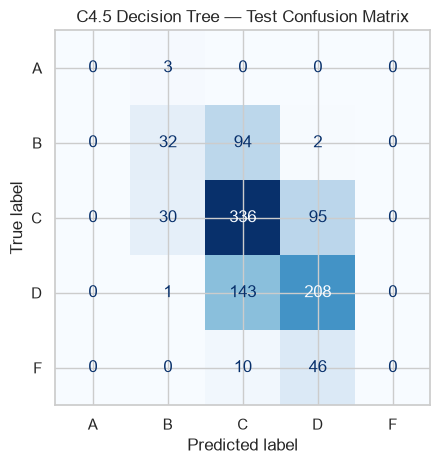

In [10]:
labels = sorted(np.unique(y))
cm = confusion_matrix(y_test, y_pred, labels=labels)
display(pd.DataFrame(cm, index=[f"Actual {x}" for x in labels],
                     columns=[f"Predicted {x}" for x in labels]))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", colorbar=False)
plt.title("C4.5 Decision Tree — Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 11. Feature importance from the learned C4.5 tree

,relative_importance
Projects_Score,0.650060
Assignments_Avg,0.189564
Midterm_Score,0.160376


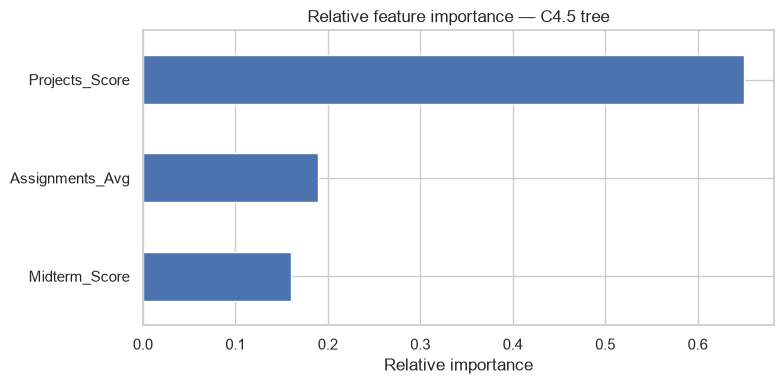

In [11]:
importance = pd.Series(collect_importance(c45_model.tree_), dtype=float)
if importance.empty or importance.sum() == 0:
    print("No split-based feature importance is available because the final tree has no splits.")
else:
    importance = (importance / importance.sum()).sort_values(ascending=False)
    display(importance.rename("relative_importance").to_frame())
    importance.sort_values().plot(kind="barh", figsize=(8, 4))
    plt.title("Relative feature importance — C4.5 tree")
    plt.xlabel("Relative importance")
    plt.tight_layout()
    plt.show()

## 12. Predict the grade of a new student

In [12]:

new_student = pd.DataFrame([{
    "Attendance (%)": 90.0,
    "Midterm_Score": 75.0,
    "Assignments_Avg": 80.0,
    "Quizzes_Avg": 78.0,
    "Participation_Score": 75.0,
    "Projects_Score": 82.0,
    "Study_Hours_per_Week": 15.0,
    "Sleep_Hours_per_Night": 7.5,
}], columns=FEATURES)

predicted_grade = c45_model.predict(new_student)[0]
print("Inputs:")
display(new_student)
print("Predicted grade:", predicted_grade)

Inputs:


,Attendance (%),Midterm_Score,Assignments_Avg,Quizzes_Avg,Participation_Score,Projects_Score,Study_Hours_per_Week,Sleep_Hours_per_Night
0,90.0,75.0,80.0,78.0,75.0,82.0,15.0,7.5


Predicted grade: C


## 13. Test multiple example inputs

In [13]:

examples = pd.DataFrame([
    {
        "Attendance (%)": 95, "Midterm_Score": 90, "Assignments_Avg": 92,
        "Quizzes_Avg": 90, "Participation_Score": 90, "Projects_Score": 94,
        "Study_Hours_per_Week": 22, "Sleep_Hours_per_Night": 8
    },
    {
        "Attendance (%)": 75, "Midterm_Score": 55, "Assignments_Avg": 60,
        "Quizzes_Avg": 58, "Participation_Score": 55, "Projects_Score": 62,
        "Study_Hours_per_Week": 8, "Sleep_Hours_per_Night": 6
    },
    {
        "Attendance (%)": 88, "Midterm_Score": 72, "Assignments_Avg": 75,
        "Quizzes_Avg": 70, "Participation_Score": 72, "Projects_Score": 76,
        "Study_Hours_per_Week": 14, "Sleep_Hours_per_Night": 7
    }
], columns=FEATURES)

examples["Predicted Grade"] = c45_model.predict(examples[FEATURES])
display(examples)

,Attendance (%),Midterm_Score,Assignments_Avg,Quizzes_Avg,Participation_Score,Projects_Score,Study_Hours_per_Week,Sleep_Hours_per_Night,Predicted Grade
0,95,90,92,90,90,94,22,8,B
1,75,55,60,58,55,62,8,6,D
2,88,72,75,70,72,76,14,7,C


# PKL FILE GENERATION

In [ ]:
import pickle

final_model = C45DecisionTree(
    max_depth=BEST_DEPTH,
    min_samples_leaf=BEST_LEAF
)

final_model.fit(X_train, y_train)
final_model.prune(X_val, y_val)

model_data = {
    "model": final_model,
    "features": FEATURES,
    "target": TARGET
}

with open("c45_grade_model.pkl", "wb") as f:
    pickle.dump(model_data, f)

print("C4.5 model saved successfully!")